In [4]:
import numpy as np
import matplotlib.pyplot as plt
import h5py as h5
from sklearn.ensemble import RandomForestRegressor as RFR
from sklearn.model_selection import train_test_split as tts
from tqdm import tqdm
from sklearn.preprocessing import StandardScaler
from seaborn import color_palette as cpal
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_validate as cv
from sklearn.metrics import roc_curve
from astroML.utils import completeness_contamination

In [5]:
f = h5.File('sample_2e7_design_precessing_higherordermodes_3detectors.h5', 'r')
fkeys = list(f.keys())
for i in range(len(fkeys)):
    print(i, fkeys[i])

0 chi1x
1 chi1y
2 chi1z
3 chi2x
4 chi2y
5 chi2z
6 dec
7 det
8 iota
9 mtot
10 psi
11 q
12 ra
13 snr
14 z


In [6]:
for k in f.keys(): lensample = f[k].size #print(lensample)
nkeys = np.shape(fkeys)[0]
nfeat = nkeys - 2

ffeat = []
X = np.zeros((nfeat, lensample))
j = 0
for i in range(nkeys):
    if i == 7: continue
    if i == 13: continue
    #print(j)
    ffeat.append(fkeys[i])
    X[j] = f[fkeys[i]]
    print(j, fkeys[i])
    j += 1

X = X.T

y = f['det']
y = np.array(y)

0 chi1x
1 chi1y
2 chi1z
3 chi2x
4 chi2y
5 chi2z
6 dec
7 iota
8 mtot
9 psi
10 q
11 ra
12 z


In [7]:
f.close()

let's work on a subsample to reduce the computing time

In [8]:
#X = X[:5000]
#y = y[:5000]
print(X.shape, y.shape)

(20000000, 13) (20000000,)


In [9]:
X_train, X_test, y_train, y_true = tts(X, y, train_size=0.67, random_state = 22)

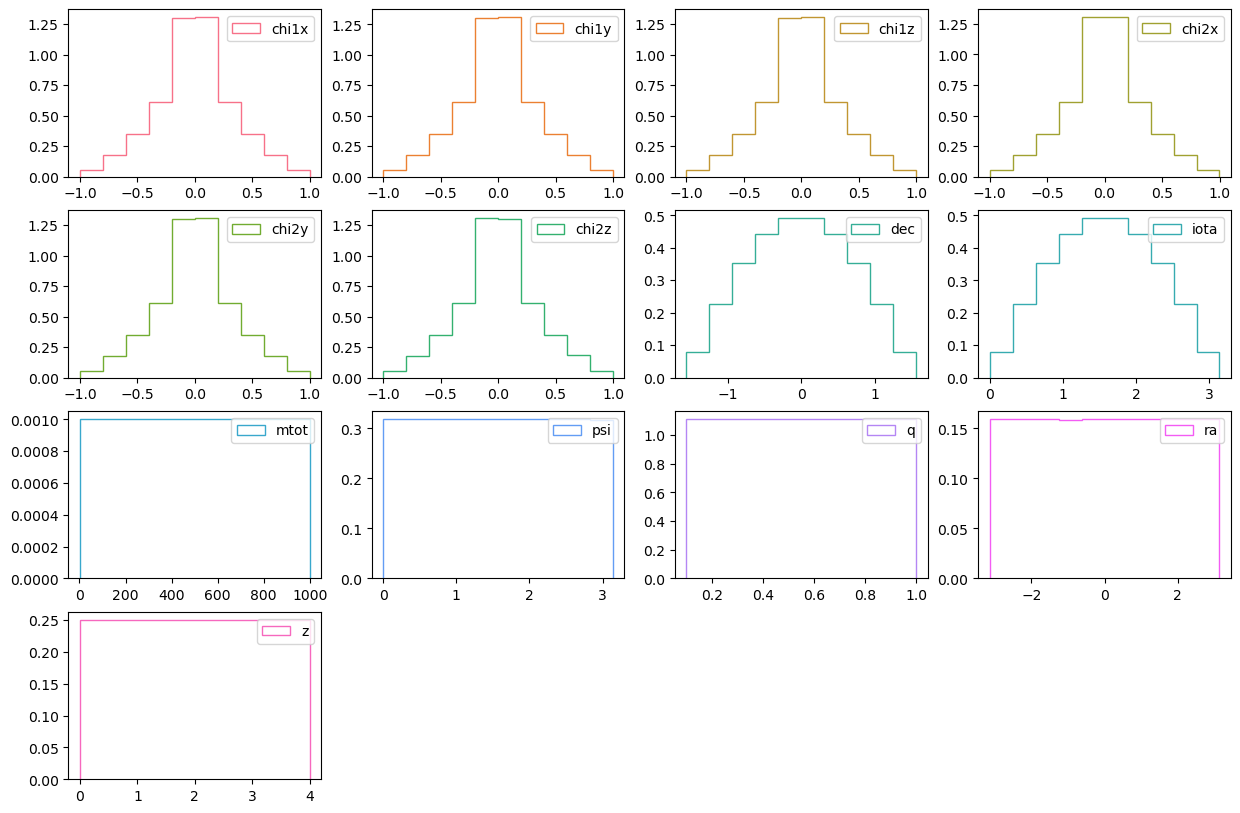

In [10]:
colors = cpal('husl', nfeat)
fig, axes = plt.subplots(ncols=4, nrows=4, figsize=(15,10))
axes = axes.flatten()
for i in range(len(axes)):
    if i >= 13:
        fig.delaxes(axes[i])
        continue
    axes[i].hist(X_train[:,i], color=colors[i], histtype='step', density=True, label=ffeat[i])
    axes[i].legend(loc='upper right')
plt.show()

In [11]:
rfr = RFR()
rfr.fit(X_train[:5000], y_train[:5000]) #had to shrink the sample which I applied the RFR on bc it got to 112 mins of execution and the process wasn't even over 
importances = rfr.feature_importances_
forder = np.argsort(importances)[::-1] #features order
print(forder)

[12  8  7 10  2  6 11  0  4  1  5  9  3]


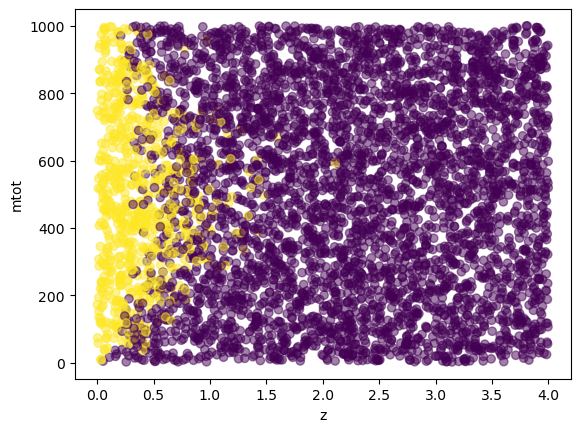

In [13]:
plt.scatter(X_train[:5000,forder[0]], X_train[:5000,forder[1]], ls='None', c=y_train[:5000], marker='o', alpha=0.5)
plt.xlabel(ffeat[forder[0]])
plt.ylabel(ffeat[forder[1]])
plt.show()

In [14]:
dtree = DecisionTreeClassifier(max_depth=3)
dtree.fit(X_train,y_train)

DecisionTreeClassifier(max_depth=3)

In [15]:
dtree.score(X_test, y_true)

0.9410318181818181

In [16]:
y_pred = dtree.predict(X_test)

In [17]:
corr = np.zeros(len(y_true))
corr[np.where(y_pred == y_true)] = 1

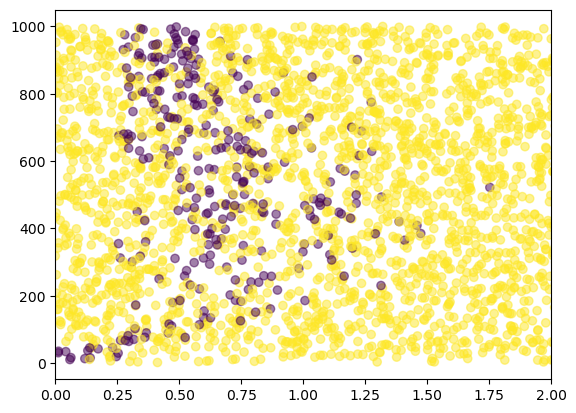

In [18]:
plt.scatter(X_test[:5000,forder[0]], X_test[:5000,forder[1]], ls='None', c=corr[:5000], marker='o', alpha=0.5)
plt.xlim(0,2)
plt.show()

* purple dots are the wrong predicted ones

Let's now perform a Cross Validation analysis

In [19]:
depths = np.linspace(2,6,3)
scores = np.zeros(len(depths))
completeness = np.zeros(len(depths))
contamination = np.zeros(len(depths))
for i in tqdm(range(len(depths))):
    depth = int(depths[i])
    dtree = DecisionTreeClassifier(max_depth=depth)
    dtree.fit(X_train, y_train)
    crossval = cv(dtree, X=X_train, y=y_train, cv=4, scoring='neg_mean_squared_error')
    scores[i] = -1*np.mean(crossval['test_score'])

    dtree.fit(X_train, y_train)
    y_pred = dtree.predict(X_test)
    completeness[i], contamination[i] = completeness_contamination(y_pred, y_true)

print(scores)

100%|██████████| 3/3 [36:50<00:00, 736.74s/it]

[0.06430045 0.05297388 0.04545858]


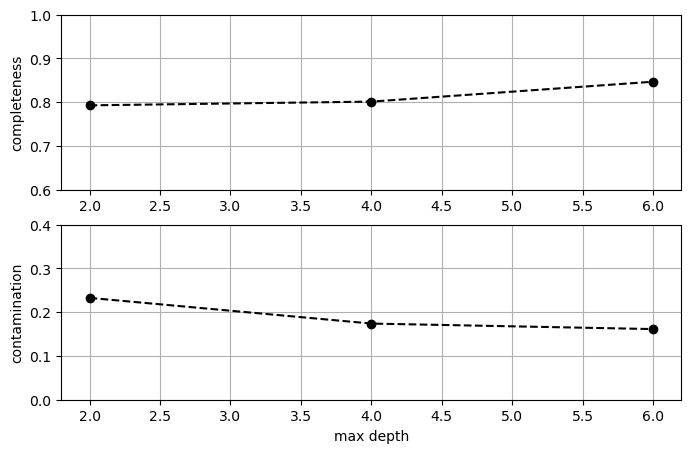

In [24]:
fig, axes = plt.subplots(nrows=2, figsize=(8,5))
axes[0].plot(depths, completeness, c='black', ls='dashed', marker='o')
axes[1].plot(depths, contamination, c='black', ls='dashed', marker='o')
axes[0].set_ylim(0.6,1)
axes[1].set_ylim(0,0.4)
axes[0].grid()
axes[1].grid()
#axes[0].set_xlabel('max depth')
axes[1].set_xlabel('max depth')
axes[0].set_ylabel('completeness')
axes[1].set_ylabel('contamination')
plt.show()

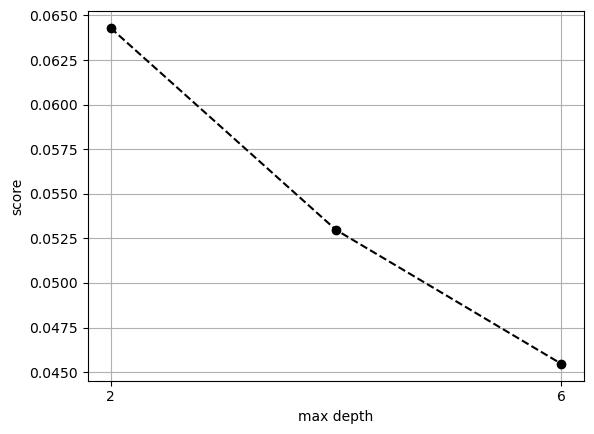

In [21]:
plt.plot(depths, scores, marker='o', c='black', ls='dashed')
plt.xlabel('max depth')
plt.ylabel('score')
plt.xticks(depths[::2])
plt.grid()
plt.show()

In [22]:
best_depth = int(depths[np.argmax(scores)])
best_depth

2

0.9353868181818182


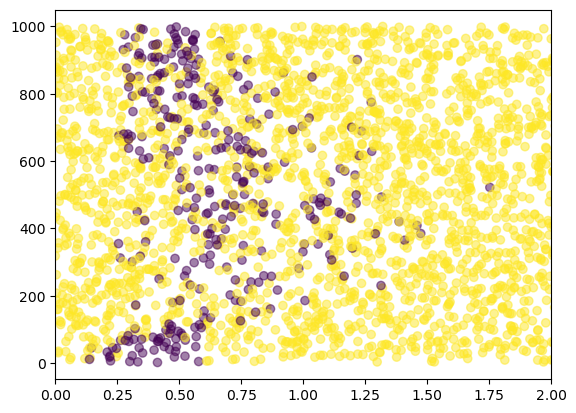

In [23]:
dtree = DecisionTreeClassifier(max_depth=best_depth)
dtree.fit(X_train,y_train)
print(dtree.score(X_test, y_true))
y_pred = dtree.predict(X_test)
corr = np.zeros(len(y_true))
corr[np.where(y_pred == y_true)] = 1
plt.scatter(X_test[:5000,forder[0]], X_test[:5000,forder[1]], ls='None', c=corr[:5000], marker='o', alpha=0.5)
plt.xlim(0,2)
plt.show()